# Women's Preventive Screening in Europe — анализ

In [88]:
import pandas as pd
from pathlib import Path

data_path = Path("../data/processed/screening_clean.csv")
df = pd.read_csv(data_path)

df.shape

(20599, 13)

## Сравнение Испании с EU 27:

In [89]:
breast_spain_eu = df[
    (df["screening_type"] == "breast_xray")
    & (df["duration"] == "Y_LT2")
    & (df["geo"].isin(["ES", "EU27_2020"]))
    & (df["year"] == 2019)
    & (df["age"] == "TOTAL")
    & (df["isced11"] == "TOTAL")
]

breast_spain_eu[
    ["country_name", "year", "duration_label", "screening_rate", "quality_flag"]
]

,country_name,year,duration_label,screening_rate,quality_flag
2905,Spain,2019,Less than 2 years,37.4,NaN
3213,European Union - 27 countries (from 2020),2019,Less than 2 years,35.4,NaN


создадим ряд где индексом будет код территории:

In [90]:
breast_rates = breast_spain_eu.set_index("geo")["screening_rate"]
breast_rates

geo
ES           37.4
EU27_2020    35.4
Name: screening_rate, dtype: float64

In [91]:
dif_breast = breast_rates.loc['ES'] - breast_rates.loc['EU27_2020']
print(f"Spain is {dif_breast:.1f} percentage points "
    "above EU 27.")

Spain is 2.0 percentage points above EU 27.


In [92]:
cervical_spain_eu = df[
    (df["screening_type"] == "cervical_smear")
    & (df["duration"] == "Y_LT3")
    & (df["geo"].isin(["ES", "EU27_2020"]))
    & (df["year"] == 2019)
    & (df["age"] == "TOTAL")
    & (df["isced11"] == "TOTAL")
]

cervical_spain_eu[
    ["country_name", "screening_rate", "quality_flag"]
]

,country_name,screening_rate,quality_flag
13020,Spain,56.0,NaN
13356,European Union - 27 countries (from 2020),59.5,NaN


In [93]:
cervical_rates = cervical_spain_eu.set_index("geo")["screening_rate"]
print(cervical_rates)
dif_cervical = cervical_rates.loc['ES'] - cervical_rates.loc['EU27_2020']
print(f"Signed difference: {dif_cervical:.1f} percentage points")
print(
    f"Spain is {abs(dif_cervical):.1f} percentage points "
    "below EU 27.")

geo
ES           56.0
EU27_2020    59.5
Name: screening_rate, dtype: float64
Signed difference: -3.5 percentage points
Spain is 3.5 percentage points below EU 27.


На 2019 год Испания выше EU 27 по обследованию груди за последние два года на 2 процентных пункта, но ниже по мазку за последние три года на 3,5 процентных пункта.

## Рейтинг стран:

In [94]:
breast_countries = df[
    (df["screening_type"] == "breast_xray")
    & (df["duration"] == "Y_LT2")
    & (df["year"] == 2019)
    & (df["age"] == "TOTAL")
    & (df["isced11"] == "TOTAL")
    & (~df["geo"].isin(["EU27_2020", "EU28"]))
].copy()

breast_countries.shape

(31, 13)

In [95]:
breast_countries["rank"] = (
    breast_countries["screening_rate"]
    .rank(ascending=False, method="min")
    .astype(int)
)

breast_ranking = breast_countries.sort_values("rank")

breast_ranking[
    ["rank", "country_name", "screening_rate", "quality_flag"]
].head(10)

,rank,country_name,screening_rate,quality_flag
8652,1,Sweden,56.6,NaN
7873,2,Portugal,46.7,NaN
5454,3,Italy,45.5,NaN
2597,4,Greece,44.8,NaN
163,5,Austria,44.7,NaN
1380,6,Czechia,44.5,NaN
5156,7,Iceland,44.0,NaN
6045,8,Luxembourg,43.9,NaN
3651,9,Finland,41.5,NaN
3944,10,France,38.3,NaN


In [96]:
breast_ranking.loc[
    breast_ranking["geo"] == "ES",
    ["rank", "country_name", "screening_rate", "quality_flag"]
]

,rank,country_name,screening_rate,quality_flag
2905,12,Spain,37.4,NaN


В 2019 году Испания занимала 12-е место среди 31 страны по доле женщин, сообщивших об обследовании груди менее двух лет назад, и находилась выше середины рейтинга.

In [97]:
cervical_countries = df[
    (df["screening_type"] == "cervical_smear")
    & (df["duration"] == "Y_LT3")
    & (df["year"] == 2019)
    & (df["age"] == "TOTAL")
    & (df["isced11"] == "TOTAL")
    & (~df["geo"].isin(["EU27_2020", "EU28"]))
].copy()

cervical_countries.shape

(31, 13)

In [98]:
cervical_countries["rank"] = (
    cervical_countries["screening_rate"]
    .rank(ascending=False, method="min")
    .astype(int)
)

cervical_ranking = cervical_countries.sort_values("rank")

cervical_ranking[
    ["rank", "country_name", "screening_rate", "quality_flag"]
].head(10)

,rank,country_name,screening_rate,quality_flag
11357,1,Czechia,83.2,NaN
16461,2,Luxembourg,77.1,NaN
10042,3,Austria,76.0,NaN
19289,4,Sweden,73.0,NaN
13848,5,Finland,69.8,NaN
11693,6,Germany,67.5,NaN
15490,7,Iceland,65.7,NaN
12684,8,Greece,65.4,NaN
16786,8,Latvia,65.4,NaN
19619,10,Slovenia,64.8,NaN


In [99]:
cervical_ranking.loc[
    cervical_ranking["geo"] == "ES",
    ["rank", "country_name", "screening_rate", "quality_flag"]
]

,rank,country_name,screening_rate,quality_flag
13020,20,Spain,56.0,NaN


В 2019 году Испания занимала 20-е место среди 31 страны по доле женщин, сообщивших об обследовании на мазок с шейки матки менее трёх лет назад, и находилась ниже середины рейтинга.

## Возрастные различия в Испании:

In [100]:
breast_es = df[
    (df["screening_type"] == "breast_xray")
    & (df["duration"] == "Y_LT2")
    & (df["year"] == 2019)
    & (df["age"] != "TOTAL")
    & (df["isced11"] == "TOTAL")
    & (df["geo"] == 'ES')
].copy()

breast_es["rank"] = (
    breast_es["screening_rate"]
    .rank(ascending=True, method="min")
    .astype(int)
)

breast_es_ranking = breast_es.sort_values("rank")

breast_es_ranking[
    ["rank", "age", "age_label",  "screening_rate", "quality_flag"]
]

,rank,age,age_label,screening_rate,quality_flag
2929,1,Y15-24,From 15 to 24 years,2.0,NaN
2953,2,Y25-34,From 25 to 34 years,10.0,NaN
2977,3,Y35-44,From 35 to 44 years,27.8,NaN
3049,4,Y_GE65,65 years or over,33.4,NaN
3001,5,Y45-54,From 45 to 54 years,61.4,NaN
3025,6,Y55-64,From 55 to 64 years,74.8,NaN


В Испании в 2019 году доля сообщивших о маммографии менее двух лет назад росла от 2,0% в группе 15–24 года до 74,8% в группе 55–64 года, после чего снижалась до 33,4% среди женщин 65 лет и старше. Возрастные различия следует интерпретировать с учётом целевых возрастов скрининга.

In [101]:
cervical_es = df[
    (df["screening_type"] == "cervical_smear")
    & (df["duration"] == "Y_LT3")
    & (df["year"] == 2019)
    & (df["age"] != "TOTAL")
    & (df["isced11"] == "TOTAL")
    & (df["geo"] == 'ES')
].copy()

cervical_es["rank"] = (
    cervical_es["screening_rate"]
    .rank(ascending=True, method="min")
    .astype(int)
)

cervical_es_ranking = cervical_es.sort_values("rank")

cervical_es_ranking[
    ["rank", "age", "age_label",  "screening_rate", "quality_flag"]
]

,rank,age,age_label,screening_rate,quality_flag
13044,1,Y15-24,From 15 to 24 years,17.8,NaN
13164,2,Y_GE65,65 years or over,28.1,NaN
13068,3,Y25-34,From 25 to 34 years,67.0,NaN
13140,4,Y55-64,From 55 to 64 years,68.3,NaN
13092,5,Y35-44,From 35 to 44 years,77.0,NaN
13116,6,Y45-54,From 45 to 54 years,77.2,NaN


В Испании в 2019 году доля сообщивших о мазке менее трёх лет назад была наиболее высокой среди женщин 35–54 лет — около 77%. Низкие показатели крайних возрастных групп следует интерпретировать с учётом того, что доступные интервалы частично выходят за возраст 20–69 лет.

## Различия по уровню образования в Испании:

In [102]:
breast_es_educ = df[
    (df["screening_type"] == "breast_xray")
    & (df["duration"] == "Y_LT2")
    & (df["year"] == 2019)
    & (df["age"] == "TOTAL")
    & (df["isced11"] != "TOTAL")
    & (df["geo"] == 'ES')
].copy()

breast_es_educ["rank"] = (
    breast_es_educ["screening_rate"]
    .rank(ascending=True, method="min")
    .astype(int)
)

breast_es_educ_ranking = breast_es_educ.sort_values("rank")

breast_es_educ_ranking[
    ["rank", "isced11", "education_label",  "screening_rate", "quality_flag"]
]

,rank,isced11,education_label,screening_rate,quality_flag
2887,1,ED0-2,"Less than primary, primary and lower secondary...",33.8,NaN
2893,2,ED3_4,Upper secondary and post-secondary non-tertiar...,38.1,NaN
2899,3,ED5-8,Tertiary education (levels 5-8),42.5,NaN


In [103]:
breast_es_educ_rates = breast_es_educ.set_index("isced11")[
    "screening_rate"
]

dif_breast_es_educ = (
    breast_es_educ_rates.loc["ED5-8"]
    - breast_es_educ_rates.loc["ED0-2"]
)

print(
    f"The education gap is {dif_breast_es_educ:.1f} "
    "percentage points."
)

The education gap is 8.7 percentage points.


В Испании показатель сообщивших о маммографии менее двух лет назад последовательно увеличивается с уровнем образования (но выборка объединяет все возрастные группы, поэтому часть различия может быть связана с разным возрастным составом образовательных групп): разница между высшим и низшим уровнем составляет 8,7 процентных пункта.

In [104]:
cervical_es_educ = df[
    (df["screening_type"] == "cervical_smear")
    & (df["duration"] == "Y_LT3")
    & (df["year"] == 2019)
    & (df["age"] == "TOTAL")
    & (df["isced11"] != "TOTAL")
    & (df["geo"] == 'ES')
].copy()

cervical_es_educ["rank"] = (
    cervical_es_educ["screening_rate"]
    .rank(ascending=True, method="min")
    .astype(int)
)

cervical_es_educ_ranking = cervical_es_educ.sort_values("rank")

cervical_es_educ_ranking[
    ["rank", "isced11", "education_label",  "screening_rate", "quality_flag"]
]



,rank,isced11,education_label,screening_rate,quality_flag
13002,1,ED0-2,"Less than primary, primary and lower secondary...",42.4,NaN
13008,2,ED3_4,Upper secondary and post-secondary non-tertiar...,60.3,NaN
13014,3,ED5-8,Tertiary education (levels 5-8),74.0,NaN


In [105]:
cervical_es_educ_rates = cervical_es_educ.set_index("isced11")[
    "screening_rate"
]

dif_cervical_es_educ = (
    cervical_es_educ_rates.loc["ED5-8"]
    - cervical_es_educ_rates.loc["ED0-2"]
)

print(
    f"The education gap is {dif_cervical_es_educ:.1f} "
    "percentage points."
)

The education gap is 31.6 percentage points.


В Испании доля сообщивших о мазке на рак шейки матки менее трёх лет назад последовательно увеличивается с уровнем образования (но выборка объединяет все возрастные группы, поэтому часть различия может быть связана с разным возрастным составом образовательных групп): разница между высшим и низшим уровнем составляет 31,6 процентных пункта.

## Изменения между 2014 и 2019 годами:

In [106]:
cervical_spain_eu_trend = df[
    (df["screening_type"] == "cervical_smear")
    & (df["duration"] == "Y_LT3")
    & (df["age"] == "TOTAL")
    & (df["isced11"] == "TOTAL")
    & (df["geo"].isin(["EU27_2020", "ES"]))
].copy()


cervical_spain_eu_trend_ranking = cervical_spain_eu_trend.sort_values(by=["geo","year"])

cervical_spain_eu_trend_ranking[
    ["geo", "country_name", "year",  "screening_rate", "quality_flag"]
]

,geo,country_name,year,screening_rate,quality_flag
12852,ES,Spain,2014,58.0,NaN
13020,ES,Spain,2019,56.0,NaN
13188,EU27_2020,European Union - 27 countries (from 2020),2014,61.4,NaN
13356,EU27_2020,European Union - 27 countries (from 2020),2019,59.5,NaN


In [107]:
cervical_spain_eu_trend_pivot = (
    cervical_spain_eu_trend
    .pivot(
        index="geo",
        columns="year",
        values="screening_rate"
    )
)

cervical_spain_eu_trend_pivot["change_2014_2019"] = (
    cervical_spain_eu_trend_pivot[2019]
    - cervical_spain_eu_trend_pivot[2014]
)

cervical_spain_eu_trend_pivot

year,2014,2019,change_2014_2019
geo,,,
ES,58.0,56.0,-2.0
EU27_2020,61.4,59.5,-1.9


Между 2014 и 2019 годами доля женщин, сообщивших о мазке менее трёх лет назад, снизилась на 2,0 процентного пункта в Испании и на 1,9 пункта в EU 27. Отставание Испании почти не изменилось: 3,4 пункта в 2014 году и 3,5 пункта в 2019 году. Доступны только две точки наблюдения, поэтому они не описывают непрерывный ежегодный тренд.

In [108]:
breast_spain_eu_duration_check = df[
    (df["screening_type"] == "breast_xray")
    & (df["duration"].isin(["Y_LT1", "Y1-2", "Y_LT2"]))
    & (df["year"] == 2019)
    & (df["age"] == "TOTAL")
    & (df["isced11"] == "TOTAL")
    & (df["geo"].isin(["ES", "EU27_2020"]))
].copy()

breast_spain_eu_duration_check_pivot = (
    breast_spain_eu_duration_check
    .pivot(
        index="geo",
        columns="duration",
        values="screening_rate"
    )
)

breast_spain_eu_duration_check_pivot["calculated_LT2"] = (
    breast_spain_eu_duration_check_pivot["Y_LT1"]
    + breast_spain_eu_duration_check_pivot["Y1-2"]
)

breast_spain_eu_duration_check_pivot["difference"] = (
    breast_spain_eu_duration_check_pivot["calculated_LT2"]
    - breast_spain_eu_duration_check_pivot["Y_LT2"]
)

breast_spain_eu_duration_check_pivot

duration,Y1-2,Y_LT1,Y_LT2,calculated_LT2,difference
geo,,,,,
ES,18.7,18.7,37.4,37.4,0.000000e+00
EU27_2020,16.6,18.8,35.4,35.4,7.105427e-15


In [109]:
breast_spain_eu_trend = df[
    (df["screening_type"] == "breast_xray")
    & (df["duration"].isin(["Y_LT1", "Y1-2"]))
    & (df["age"] == "TOTAL")
    & (df["isced11"] == "TOTAL")
    & (df["geo"].isin(["ES", "EU27_2020"]))
].copy()

breast_spain_eu_trend.groupby(
    ["geo", "year"]
).size()

geo        year
ES         2014    2
           2019    2
EU27_2020  2014    2
           2019    2
dtype: int64

In [110]:
breast_spain_eu_trend_calc = (
    breast_spain_eu_trend
    .groupby(
        ["geo", "country_name", "year"],
        as_index=False
    )
    .agg(
        screening_rate=("screening_rate", "sum"),
        quality_flag_count=(
            "quality_flag",
            lambda values: values.notna().sum()
        )
    )
)

breast_spain_eu_trend_calc

,geo,country_name,year,screening_rate,quality_flag_count
0,ES,Spain,2014,38.5,0
1,ES,Spain,2019,37.4,0
2,EU27_2020,European Union - 27 countries (from 2020),2014,36.6,0
3,EU27_2020,European Union - 27 countries (from 2020),2019,35.4,0


In [111]:
breast_spain_eu_trend_pivot = (
    breast_spain_eu_trend_calc
    .pivot(
        index="geo",
        columns="year",
        values="screening_rate"
    )
)

breast_spain_eu_trend_pivot["change_2014_2019"] = (
    breast_spain_eu_trend_pivot[2019]
    - breast_spain_eu_trend_pivot[2014]
)

breast_spain_eu_trend_pivot

year,2014,2019,change_2014_2019
geo,,,
ES,38.5,37.4,-1.1
EU27_2020,36.6,35.4,-1.2


Для сравнения 2014 и 2019 годов показатель «маммография менее двух лет назад» рассчитан как сумма непересекающихся категорий Y_LT1 и Y1-2. Формула проверена по готовому Y_LT2 за 2019 год. Между 2014 и 2019 годами показатель снизился на 1,1 процентного пункта в Испании и на 1,2 пункта в EU 27. Преимущество Испании почти не изменилось: 1,9 пункта в 2014 году и 2,0 пункта в 2019 году.

 ## Образовательный разрыв между странами:

проверяем, сколько стран имеют данные по всем трём уровням образования:

In [112]:
cervical_countries_educ = df[
    (df["screening_type"] == "cervical_smear")
    & (df["duration"] == "Y_LT3")
    & (df["year"] == 2019)
    & (df["age"] == "TOTAL")
    & (df["isced11"] != "TOTAL")
    & (~df["geo"].isin(["EU27_2020", "EU28"]))
].copy()

cervical_countries_educ.groupby("geo")["isced11"].nunique().value_counts()

isced11
3    31
Name: count, dtype: int64

все 31 страна имеют данные по трём уровням образования.
Теперь перестроим данные и рассчитаем разрыв:

In [113]:
cervical_countries_educ_pivot = (
    cervical_countries_educ
    .pivot(
        index=["geo", "country_name"],
        columns="isced11",
        values="screening_rate"
    )
    .reset_index()
)

cervical_countries_educ_pivot["educ_gap"] = (
    cervical_countries_educ_pivot["ED5-8"]
    - cervical_countries_educ_pivot["ED0-2"]
)

cervical_countries_educ_pivot["educ_gap_abs"] = (
    cervical_countries_educ_pivot["educ_gap"].abs()
)

cervical_countries_educ_gap = (
    cervical_countries_educ_pivot
    .sort_values("educ_gap_abs", ascending=False)
)

cervical_countries_educ_gap[
    [
        "country_name",
        "ED0-2",
        "ED3_4",
        "ED5-8",
        "educ_gap",
        "educ_gap_abs",
    ]
].head(10)

isced11,country_name,ED0-2,ED3_4,ED5-8,educ_gap,educ_gap_abs
23,Poland,26.4,62.8,83.6,57.2,57.2
3,Cyprus,29.7,60.0,77.8,48.1,48.1
19,Latvia,32.5,65.6,80.3,47.8,47.8
2,Bulgaria,18.4,47.3,65.5,47.1,47.1
26,Serbia,26.6,57.9,73.6,47.0,47.0
8,Greece,38.9,75.4,85.4,46.5,46.5
29,Slovakia,32.6,65.5,79.1,46.5,46.5
12,Croatia,33.4,67.3,79.5,46.1,46.1
10,Finland,39.5,72.6,84.6,45.1,45.1
17,Lithuania,20.8,52.9,64.9,44.1,44.1


проверим качество исходных значений первой десятки:

In [114]:
top_cervical_educ_geo = (
    cervical_countries_educ_gap
    .head(10)["geo"]
)

cervical_countries_educ[
    cervical_countries_educ["geo"].isin(top_cervical_educ_geo)
    & cervical_countries_educ["quality_flag"].notna()
][
    [
        "country_name",
        "isced11",
        "screening_rate",
        "quality_flag",
        "quality_flag_label",
    ]
]

,country_name,isced11,screening_rate,quality_flag,quality_flag_label


Пустая таблица означает, что у значений первой десятки нет флагов качества Eurostat. Поэтому их можно использовать без дополнительного предупреждения о u или d.
Теперь определи место Испании по размеру образовательного разрыва:

In [115]:
cervical_countries_educ_gap["rank"] = (
    cervical_countries_educ_gap["educ_gap_abs"]
    .rank(ascending=False, method="min")
    .astype(int)
)

cervical_countries_educ_gap.loc[
    cervical_countries_educ_gap["geo"] == "ES",
    [
        "rank",
        "country_name",
        "ED0-2",
        "ED5-8",
        "educ_gap",
        "educ_gap_abs",
    ]
]

isced11,rank,country_name,ED0-2,ED5-8,educ_gap,educ_gap_abs
9,22,Spain,42.4,74.0,31.6,31.6


В 2019 году крупнейший образовательный разрыв по доле сообщивших о мазке менее трёх лет назад наблюдался в Польше — 57,2 процентного пункта. В Испании разрыв составлял 31,6 пункта, что соответствовало 22-му месту среди 31 страны. Расчёт объединяет все возрастные группы, поэтому часть различий может быть связана с их возрастным составом.

In [116]:
breast_countries_educ = df[
    (df["screening_type"] == "breast_xray")
    & (df["duration"] == "Y_LT2")
    & (df["year"] == 2019)
    & (df["age"] == "TOTAL")
    & (df["isced11"] != "TOTAL")
    & (~df["geo"].isin(["EU27_2020", "EU28"]))
].copy()

breast_countries_educ.groupby("geo")["isced11"].nunique().value_counts()

isced11
3    31
Name: count, dtype: int64

In [117]:
breast_countries_educ_pivot = (
    breast_countries_educ
    .pivot(
        index=["geo", "country_name"],
        columns="isced11",
        values="screening_rate"
    )
    .reset_index()
)

breast_countries_educ_pivot["educ_gap"] = (
    breast_countries_educ_pivot["ED5-8"]
    - breast_countries_educ_pivot["ED0-2"]
)

breast_countries_educ_pivot["educ_gap_abs"] = (
    breast_countries_educ_pivot["educ_gap"].abs()
)

breast_countries_educ_gap = (
    breast_countries_educ_pivot
    .sort_values("educ_gap_abs", ascending=False)
)

breast_countries_educ_gap[
    [
        "country_name",
        "ED0-2",
        "ED3_4",
        "ED5-8",
        "educ_gap",
        "educ_gap_abs",
    ]
].head(10)

isced11,country_name,ED0-2,ED3_4,ED5-8,educ_gap,educ_gap_abs
2,Bulgaria,9.5,25.8,42.0,32.5,32.5
8,Greece,30.9,50.0,55.3,24.4,24.4
13,Hungary,21.1,37.9,42.9,21.8,21.8
19,Latvia,9.3,29.8,27.0,17.7,17.7
29,Slovakia,21.2,42.1,38.2,17.0,17.0
17,Lithuania,12.6,30.9,28.6,16.0,16.0
20,Malta,33.8,17.6,18.3,-15.5,15.5
10,Finland,31.2,43.3,45.8,14.6,14.6
7,Estonia,11.1,21.1,25.6,14.5,14.5
23,Poland,13.2,29.8,24.7,11.5,11.5


In [118]:
top_breast_educ_geo = (
    breast_countries_educ_gap
    .head(10)["geo"]
)

breast_countries_educ[
    breast_countries_educ["geo"].isin(top_breast_educ_geo)
    & breast_countries_educ["quality_flag"].notna()
][
    [
        "country_name",
        "isced11",
        "screening_rate",
        "quality_flag",
        "quality_flag_label",
    ]
]

,country_name,isced11,screening_rate,quality_flag,quality_flag_label


In [119]:
breast_countries_educ_gap["rank"] = (
    breast_countries_educ_gap["educ_gap_abs"]
    .rank(ascending=False, method="min")
    .astype(int)
)

breast_countries_educ_gap.loc[
    breast_countries_educ_gap["geo"] == "ES",
    [
        "rank",
        "country_name",
        "ED0-2",
        "ED5-8",
        "educ_gap",
        "educ_gap_abs",
    ]
]

isced11,rank,country_name,ED0-2,ED5-8,educ_gap,educ_gap_abs
9,17,Spain,33.8,42.5,8.7,8.7


В 2019 году крупнейший образовательный разрыв по доле сообщивших о обследовании груди менее двух лет назад наблюдался в Болгарии — 32,5 процентного пункта. В Испании разрыв составлял 8,7 пункта, что соответствовало 17-му месту среди 31 страны. Расчёт объединяет все возрастные группы, поэтому часть различий может быть связана с их возрастным составом.

## Визуализации:

In [120]:
import matplotlib.pyplot as plt

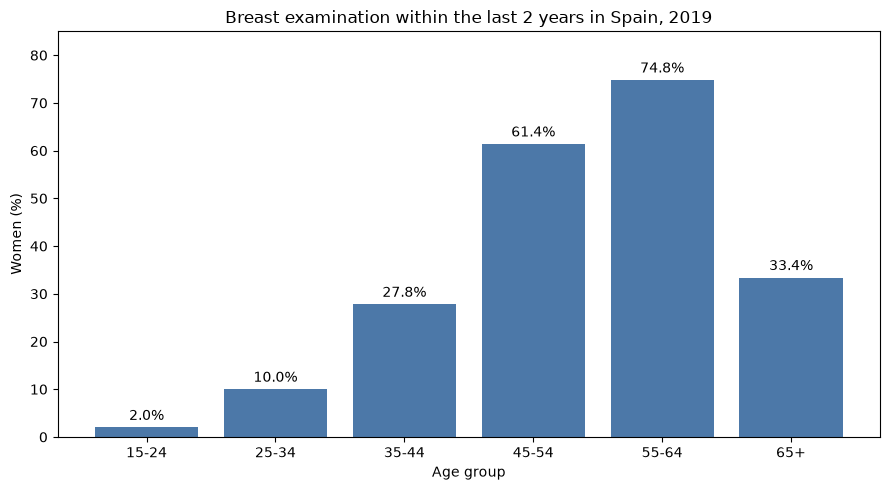

In [121]:
age_order = [
    "Y15-24",
    "Y25-34",
    "Y35-44",
    "Y45-54",
    "Y55-64",
    "Y_GE65",
]

age_labels = [
    "15-24",
    "25-34",
    "35-44",
    "45-54",
    "55-64",
    "65+",
]

breast_es_plot = (
    breast_es
    .set_index("age")
    .loc[age_order]
    .reset_index()
)

fig_breast, ax_breast = plt.subplots(figsize=(9, 5))

bars_breast = ax_breast.bar(
    age_labels,
    breast_es_plot["screening_rate"],
    color="#4C78A8",
)

ax_breast.bar_label(
    bars_breast,
    fmt="%.1f%%",
    padding=3,
)

ax_breast.set_title(
    "Breast examination within the last 2 years in Spain, 2019"
)
ax_breast.set_xlabel("Age group")
ax_breast.set_ylabel("Women (%)")
ax_breast.set_ylim(0, 85)

plt.tight_layout()
plt.show()

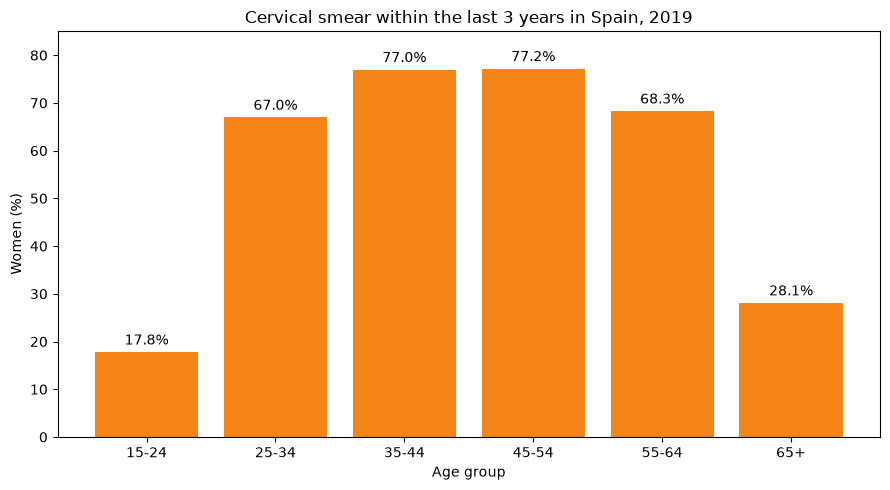

In [122]:
cervical_es_plot = (
    cervical_es
    .set_index("age")
    .loc[age_order]
    .reset_index()
)

fig_cervical, ax_cervical = plt.subplots(figsize=(9, 5))

bars_cervical = ax_cervical.bar(
    age_labels,
    cervical_es_plot["screening_rate"],
    color="#F58518",
)

ax_cervical.bar_label(
    bars_cervical,
    fmt="%.1f%%",
    padding=3,
)

ax_cervical.set_title(
    "Cervical smear within the last 3 years in Spain, 2019"
)
ax_cervical.set_xlabel("Age group")
ax_cervical.set_ylabel("Women (%)")
ax_cervical.set_ylim(0, 85)

plt.tight_layout()
plt.show()

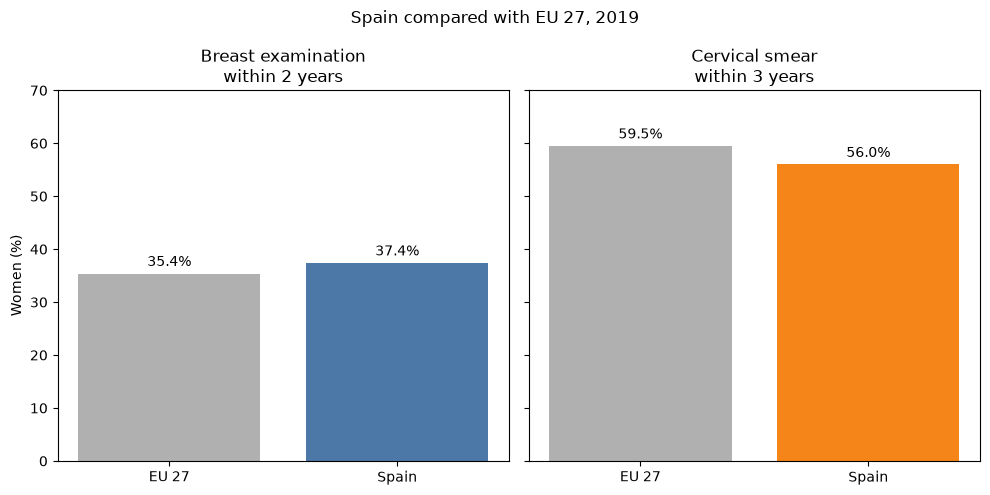

In [123]:
geo_order = ["EU27_2020", "ES"]
geo_labels = ["EU 27", "Spain"]

breast_spain_eu_plot = (
    breast_spain_eu
    .set_index("geo")
    .loc[geo_order]
    .reset_index()
)

cervical_spain_eu_plot = (
    cervical_spain_eu
    .set_index("geo")
    .loc[geo_order]
    .reset_index()
)

fig_comparison, (
    ax_breast_comparison,
    ax_cervical_comparison,
) = plt.subplots(
    1,
    2,
    figsize=(10, 5),
    sharey=True,
)

bars_breast_comparison = ax_breast_comparison.bar(
    geo_labels,
    breast_spain_eu_plot["screening_rate"],
    color=["#B0B0B0", "#4C78A8"],
)

bars_cervical_comparison = ax_cervical_comparison.bar(
    geo_labels,
    cervical_spain_eu_plot["screening_rate"],
    color=["#B0B0B0", "#F58518"],
)

ax_breast_comparison.bar_label(
    bars_breast_comparison,
    fmt="%.1f%%",
    padding=3,
)

ax_cervical_comparison.bar_label(
    bars_cervical_comparison,
    fmt="%.1f%%",
    padding=3,
)

ax_breast_comparison.set_title("Breast examination\nwithin 2 years")
ax_cervical_comparison.set_title("Cervical smear\nwithin 3 years")

ax_breast_comparison.set_ylabel("Women (%)")
ax_breast_comparison.set_ylim(0, 70)

fig_comparison.suptitle("Spain compared with EU 27, 2019")

plt.tight_layout()
plt.show()

построим динамику мазка между двумя доступными волнами исследования:

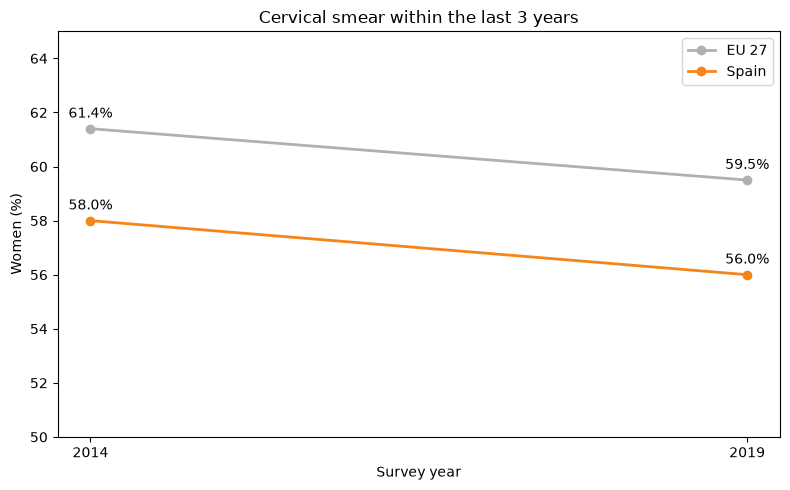

In [124]:
fig_cervical_trend, ax_cervical_trend = plt.subplots(
    figsize=(8, 5)
)

trend_colors = {
    "EU27_2020": "#B0B0B0",
    "ES": "#F58518",
}

trend_labels = {
    "EU27_2020": "EU 27",
    "ES": "Spain",
}

for geo_code in ["EU27_2020", "ES"]:
    cervical_trend_line = (
        cervical_spain_eu_trend[
            cervical_spain_eu_trend["geo"] == geo_code
        ]
        .sort_values("year")
    )

    ax_cervical_trend.plot(
        cervical_trend_line["year"],
        cervical_trend_line["screening_rate"],
        marker="o",
        linewidth=2,
        color=trend_colors[geo_code],
        label=trend_labels[geo_code],
    )

    for _, row in cervical_trend_line.iterrows():
        ax_cervical_trend.annotate(
            f'{row["screening_rate"]:.1f}%',
            (row["year"], row["screening_rate"]),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center",
        )

ax_cervical_trend.set_title(
    "Cervical smear within the last 3 years"
)
ax_cervical_trend.set_xlabel("Survey year")
ax_cervical_trend.set_ylabel("Women (%)")
ax_cervical_trend.set_xticks([2014, 2019])
ax_cervical_trend.set_ylim(50, 65)
ax_cervical_trend.legend()

plt.tight_layout()
plt.show()

построим динамику маммографии по двум волнам исследования:

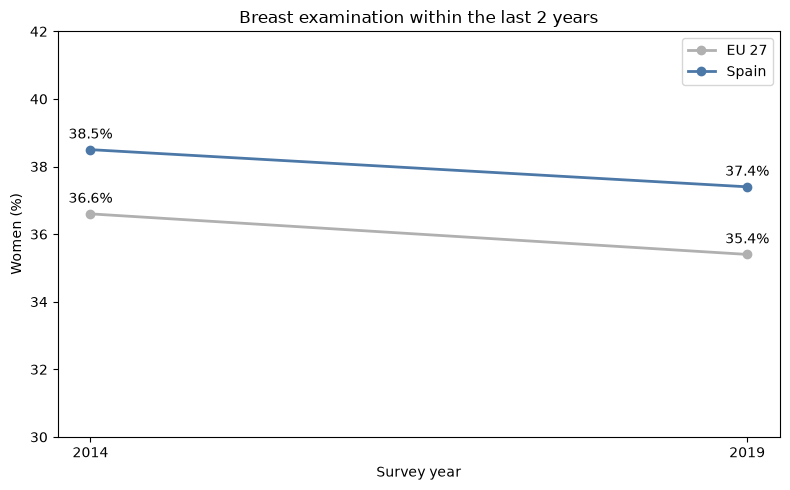

In [125]:
fig_breast_trend, ax_breast_trend = plt.subplots(
    figsize=(8, 5)
)

trend_colors = {
    "EU27_2020": "#B0B0B0",
    "ES": "#4C78A8",
}

trend_labels = {
    "EU27_2020": "EU 27",
    "ES": "Spain",
}

for geo_code in ["EU27_2020", "ES"]:
    breast_trend_line = (
    breast_spain_eu_trend_calc[
        breast_spain_eu_trend_calc["geo"] == geo_code
    ]
    .sort_values("year")
    )

    ax_breast_trend.plot(
        breast_trend_line["year"],
        breast_trend_line["screening_rate"],
        marker="o",
        linewidth=2,
        color=trend_colors[geo_code],
        label=trend_labels[geo_code],
    )

    for _, row in breast_trend_line.iterrows():
        ax_breast_trend.annotate(
            f'{row["screening_rate"]:.1f}%',
            (row["year"], row["screening_rate"]),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center",
        )

ax_breast_trend.set_title(
    "Breast examination within the last 2 years"
)
ax_breast_trend.set_xlabel("Survey year")
ax_breast_trend.set_ylabel("Women (%)")
ax_breast_trend.set_xticks([2014, 2019])
ax_breast_trend.set_ylim(30, 42)
ax_breast_trend.legend()

plt.tight_layout()
plt.show()

График для образовательного неравенства. Он покажет десять стран с крупнейшим разрывом по мазку и отдельно Испанию:

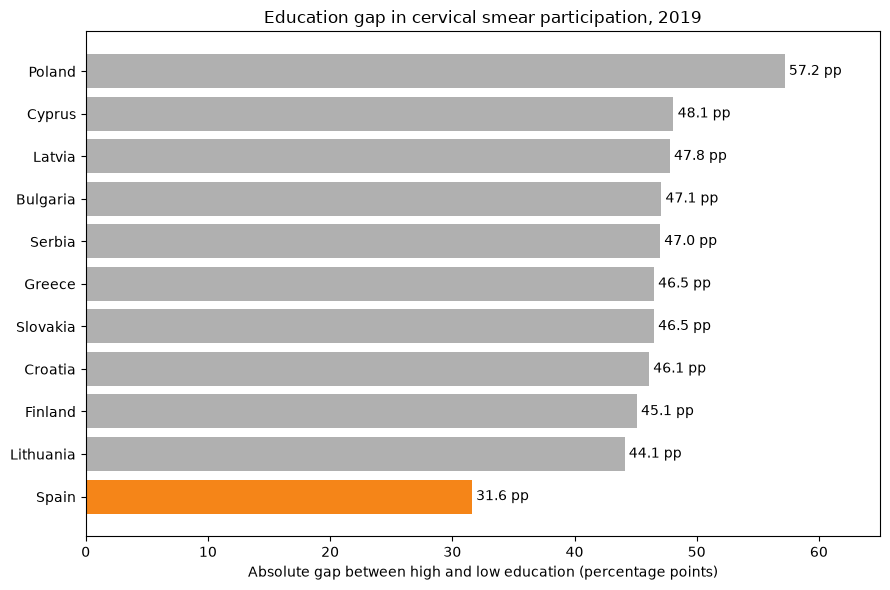

In [126]:
cervical_educ_gap_plot = pd.concat(
    [
        cervical_countries_educ_gap.head(10),
        cervical_countries_educ_gap[
            cervical_countries_educ_gap["geo"] == "ES"
        ],
    ]
).drop_duplicates("geo")

cervical_educ_gap_plot = cervical_educ_gap_plot.sort_values(
    "educ_gap_abs"
)

gap_colors = [
    "#F58518" if geo == "ES" else "#B0B0B0"
    for geo in cervical_educ_gap_plot["geo"]
]

fig_cervical_gap, ax_cervical_gap = plt.subplots(
    figsize=(9, 6)
)

bars_cervical_gap = ax_cervical_gap.barh(
    cervical_educ_gap_plot["country_name"],
    cervical_educ_gap_plot["educ_gap_abs"],
    color=gap_colors,
)

ax_cervical_gap.bar_label(
    bars_cervical_gap,
    fmt="%.1f pp",
    padding=3,
)

ax_cervical_gap.set_title(
    "Education gap in cervical smear participation, 2019"
)
ax_cervical_gap.set_xlabel(
    "Absolute gap between high and low education (percentage points)"
)
ax_cervical_gap.set_xlim(0, 65)

plt.tight_layout()
plt.show()

График образовательного разрыва по груди:

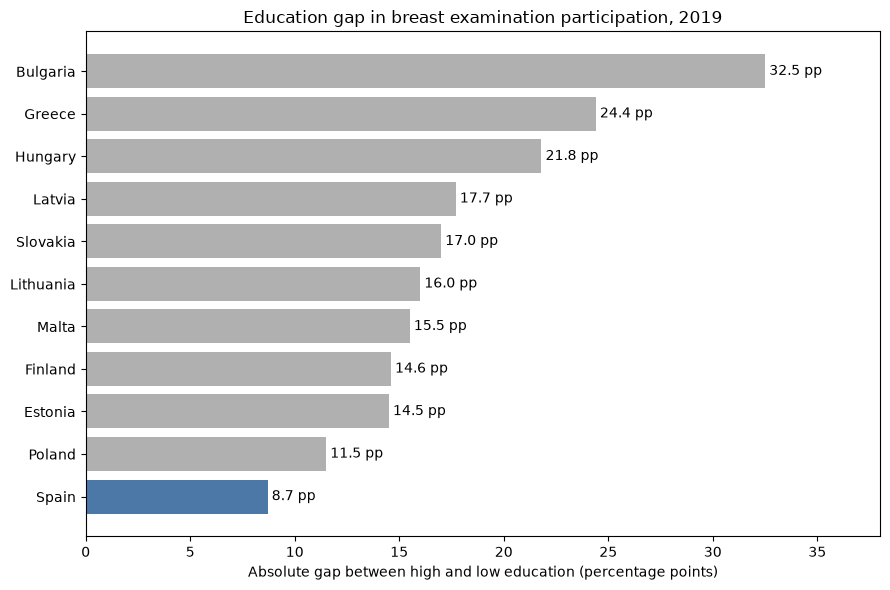

In [127]:
breast_educ_gap_plot = pd.concat(
    [
        breast_countries_educ_gap.head(10),
        breast_countries_educ_gap[
            breast_countries_educ_gap["geo"] == "ES"
        ],
    ]
).drop_duplicates("geo")

breast_educ_gap_plot = breast_educ_gap_plot.sort_values(
    "educ_gap_abs"
)

breast_gap_colors = [
    "#4C78A8" if geo == "ES" else "#B0B0B0"
    for geo in breast_educ_gap_plot["geo"]
]

fig_breast_gap, ax_breast_gap = plt.subplots(
    figsize=(9, 6)
)

bars_breast_gap = ax_breast_gap.barh(
    breast_educ_gap_plot["country_name"],
    breast_educ_gap_plot["educ_gap_abs"],
    color=breast_gap_colors,
)

ax_breast_gap.bar_label(
    bars_breast_gap,
    fmt="%.1f pp",
    padding=3,
)

ax_breast_gap.set_title(
    "Education gap in breast examination participation, 2019"
)
ax_breast_gap.set_xlabel(
    "Absolute gap between high and low education (percentage points)"
)
ax_breast_gap.set_xlim(0, 38)

plt.tight_layout()
plt.show()